# **INTRODUCTION**
This notebook explores community structure in the Karate Club
network using spectral community detection.

The Karate Club graph consists of 34 nodes and 78 edges. Each node
represents a member of the club, and each edge represents a connection
between two members.

The analysis uses the modularity matrix and its eigenvalues
and eigenvectors to divide the network into smaller communities.
We also study different centrality measures to understand the
importance and structural roles of individual nodes.

In [113]:

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

print("All libraries imported successfully!")


All libraries imported successfully!


In [114]:

# Load the famous Karate Club graph
karate_graph = nx.karate_club_graph()

# Print basic information
print("Number of nodes:", karate_graph.number_of_nodes())
print("Number of edges:", karate_graph.number_of_edges())
print("Nodes:", list(karate_graph.nodes()))


Number of nodes: 34
Number of edges: 78
Nodes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]


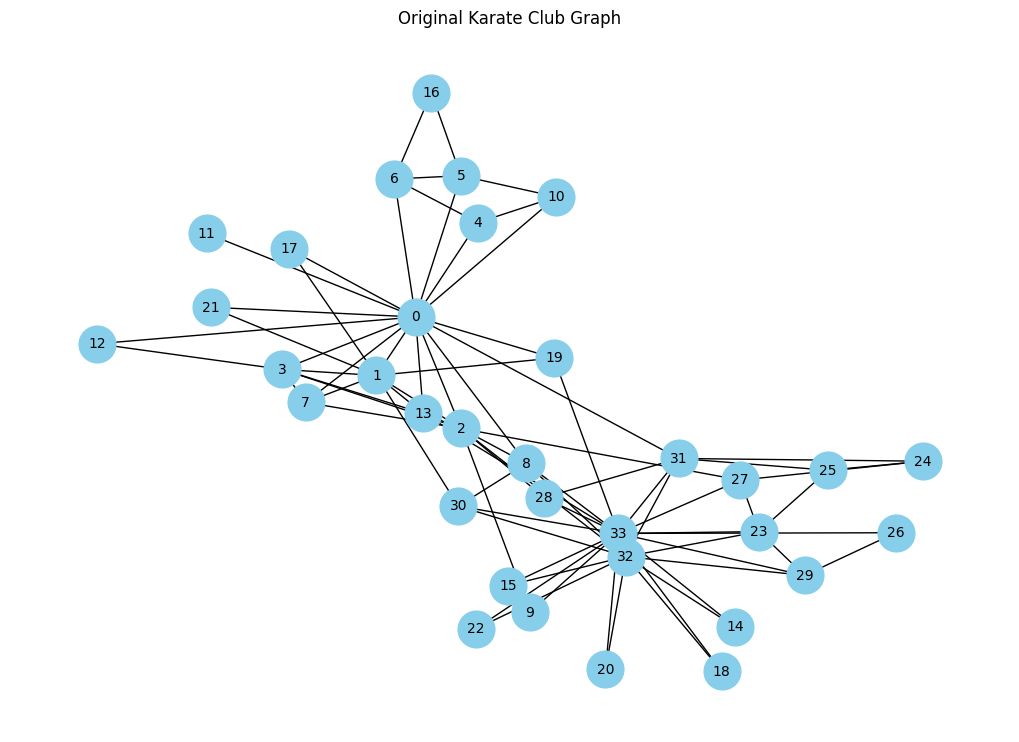

In [115]:

# Create a fixed layout for the graph
pos = nx.spring_layout(karate_graph, seed=42)

# Draw the graph
plt.figure(figsize=(10, 7))

nx.draw(
    karate_graph,
    pos,
    with_labels=True,
    node_color="skyblue",
    node_size=700,
    font_size=10,
    edge_color="black"
)

plt.title("Original Karate Club Graph")
plt.show()


In [116]:

# Calculate degree of every node
for node in karate_graph.nodes():
    print("Node", node, "has degree", karate_graph.degree(node))


Node 0 has degree 16
Node 1 has degree 9
Node 2 has degree 10
Node 3 has degree 6
Node 4 has degree 3
Node 5 has degree 4
Node 6 has degree 4
Node 7 has degree 4
Node 8 has degree 5
Node 9 has degree 2
Node 10 has degree 3
Node 11 has degree 1
Node 12 has degree 2
Node 13 has degree 5
Node 14 has degree 2
Node 15 has degree 2
Node 16 has degree 2
Node 17 has degree 2
Node 18 has degree 2
Node 19 has degree 3
Node 20 has degree 2
Node 21 has degree 2
Node 22 has degree 2
Node 23 has degree 5
Node 24 has degree 3
Node 25 has degree 3
Node 26 has degree 2
Node 27 has degree 4
Node 28 has degree 3
Node 29 has degree 4
Node 30 has degree 4
Node 31 has degree 6
Node 32 has degree 12
Node 33 has degree 17


In [117]:

# nx.to_numpy_array(G) converts our graph into a matrix.
adjacency = nx.to_numpy_array(karate_graph , weight = None)

print("Adjacency Matrix:")
print(adjacency)

print("Shape of matrix:", adjacency.shape)
print(np.sum(adjacency))


Adjacency Matrix:
[[0. 1. 1. ... 1. 0. 0.]
 [1. 0. 1. ... 0. 0. 0.]
 [1. 1. 0. ... 0. 1. 0.]
 ...
 [1. 0. 0. ... 0. 1. 1.]
 [0. 0. 1. ... 1. 0. 1.]
 [0. 0. 0. ... 1. 1. 0.]]
Shape of matrix: (34, 34)
156.0


In [118]:
# understanding matrix
print("Node 0 connected to Node 1:", adjacency[0, 1])
print("Node 0 connected to Node 2:", adjacency[0, 2])


Node 0 connected to Node 1: 1.0
Node 0 connected to Node 2: 1.0


In [119]:
# calculate degree vector
node_degrees = np.sum(adjacency, axis=1)

print("Degree vector:")
print(node_degrees)

print("Number of nodes:", len(node_degrees))
print("Sum of all degrees:", np.sum(node_degrees))
print(np.sum(node_degrees))


Degree vector:
[16.  9. 10.  6.  3.  4.  4.  4.  5.  2.  3.  1.  2.  5.  2.  2.  2.  2.
  2.  3.  2.  2.  2.  5.  3.  3.  2.  4.  3.  4.  4.  6. 12. 17.]
Number of nodes: 34
Sum of all degrees: 156.0
156.0


### Modularity Matrix
The modularity matrix is defined as:

B = A - (kkᵀ / 2m)

Where:

- A is the adjacency matrix of the graph.
- k is the degree vector of all nodes.
- m is the total number of edges.

The adjacency matrix is constructed without edge weights so that
every connection is treated equally.

The modularity matrix helps identify groups of nodes that have
more connections within their community than expected in a
random network.

In [120]:
# calculate modularity matrix
edge_total = karate_graph.number_of_edges()

modularity = adjacency - np.outer(node_degrees, node_degrees) / (2 * edge_total)

print("Modularity Matrix B:")
print(modularity)

print("Shape of B:", modularity.shape)


Modularity Matrix B:
[[-1.64102564  0.07692308 -0.02564103 ...  0.38461538 -1.23076923
  -1.74358974]
 [ 0.07692308 -0.51923077  0.42307692 ... -0.34615385 -0.69230769
  -0.98076923]
 [-0.02564103  0.42307692 -0.64102564 ... -0.38461538  0.23076923
  -1.08974359]
 ...
 [ 0.38461538 -0.34615385 -0.38461538 ... -0.23076923  0.53846154
   0.34615385]
 [-1.23076923 -0.69230769  0.23076923 ...  0.53846154 -0.92307692
  -0.30769231]
 [-1.74358974 -0.98076923 -1.08974359 ...  0.34615385 -0.30769231
  -1.8525641 ]]
Shape of B: (34, 34)


In [121]:
# check if B is symmetric
print("Is B symmetric?", np.allclose(modularity, modularity.T))
print("Sum of all entries of B:", np.sum(modularity))
print(np.sum(modularity))

Is B symmetric? True
Sum of all entries of B: -3.774758283725532e-15
-3.774758283725532e-15


### Spectral community detection
Spectral community detection uses the eigenvalues and eigenvectors
of the modularity matrix to divide a network into communities.

The leading eigenvector is used to assign nodes to two groups
according to the signs of its components.

- Positive components are assigned to one group.
- Negative components are assigned to the other group.

The process is repeated recursively on the resulting communities.

A community is considered for further splitting when its largest
eigenvalue is positive and the resulting division contains two
non-empty groups.

In [122]:

# Calculate eigenvalues and eigenvectors
evals, evecs = np.linalg.eigh(modularity)

# Find the largest eigenvalue
top_eval = evals[-1]

# Find its corresponding eigenvector
top_evec = evecs[:, -1]

print("Largest eigenvalue:", top_eval)

print("\nLeading eigenvector:")
print(top_evec)

print("\nNumber of components:", len(top_evec))


Largest eigenvalue: 4.977080225729887

Leading eigenvector:
[ 0.38754293  0.26955742  0.13189899  0.25345236  0.13400323  0.14573804
  0.14573804  0.20935954 -0.05447571 -0.04785238  0.13400323  0.07784279
  0.12874396  0.13502861 -0.13943288 -0.13943288  0.05851821  0.13197981
 -0.13943288  0.05764888 -0.13943288  0.13197981 -0.13943288 -0.21674712
 -0.0563305  -0.07540039 -0.11580257 -0.10276487 -0.06834027 -0.20629456
 -0.09626391 -0.10185678 -0.32390453 -0.36983786]

Number of components: 34


In [123]:
# dividing communities base on eigenvector components
initial_signs = np.where(top_evec > 0, 1, -1)

print("Community labels:")
print(initial_signs)

print("\nNumber of nodes in Community 1:",
      np.sum(initial_signs == 1))

print("Number of nodes in Community 2:",
      np.sum(initial_signs == -1))


Community labels:
[ 1  1  1  1  1  1  1  1 -1 -1  1  1  1  1 -1 -1  1  1 -1  1 -1  1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1]

Number of nodes in Community 1: 16
Number of nodes in Community 2: 18


In [124]:
# print which note belong to which community

group_positive = [
    node for node in karate_graph.nodes()
    if initial_signs[node] == 1
]

group_negative = [
    node for node in karate_graph.nodes()
    if initial_signs[node] == -1
]

print("Community 1:", group_positive)
print("Community 2:", group_negative)


Community 1: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Community 2: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]


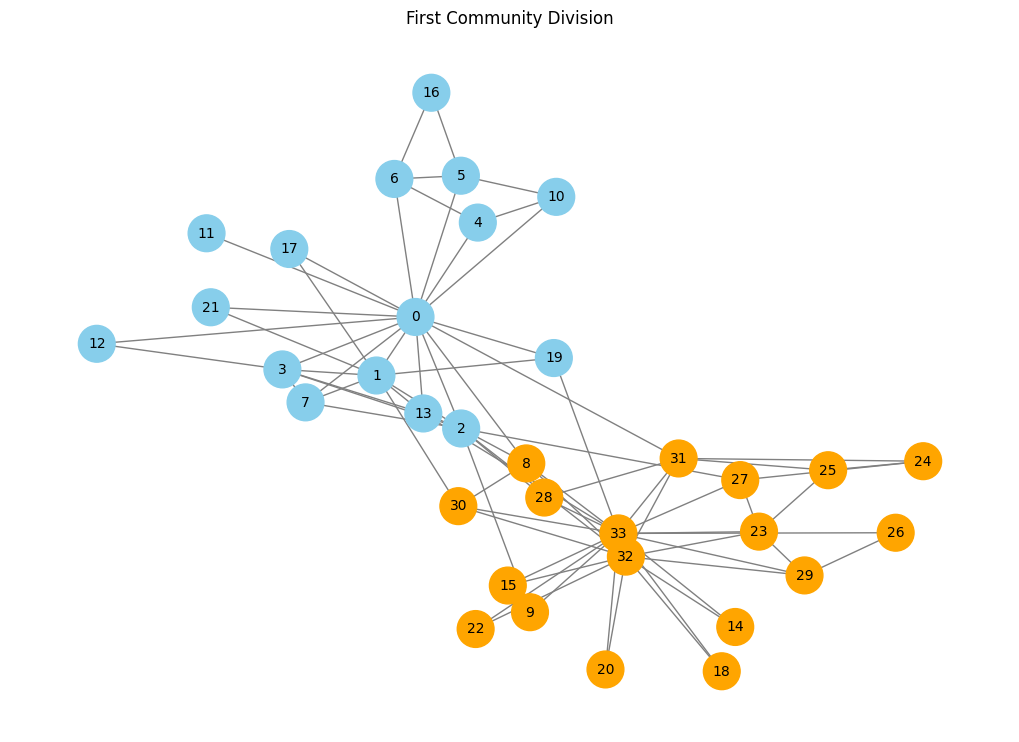

In [125]:
# visualizing our first split
colors = [
    "skyblue" if initial_signs[node] == 1 else "orange"
    for node in karate_graph.nodes()
]

plt.figure(figsize=(10, 7))

nx.draw(
    karate_graph,
    pos,
    with_labels=True,
    node_color=colors,
    node_size=700,
    font_size=10,
    edge_color="gray"
)

plt.title("First Community Division")
plt.show()


In [126]:
print("Unique values in A:", np.unique(adjacency))
print("Sum of A:", np.sum(adjacency))
print("Sum of k:", np.sum(node_degrees))
print("m:", edge_total)

print("Largest eigenvalue:", evals[-1])

print("Eigenvector check:",
      np.allclose(modularity @ top_evec,
                  top_eval * top_evec))


Unique values in A: [0. 1.]
Sum of A: 156.0
Sum of k: 156.0
m: 78
Largest eigenvalue: 4.977080225729887
Eigenvector check: True
Current numerator: 115.89743589743591


In [127]:
s = initial_signs
print(np.array_equal(s, initial_signs))
Q = (s.T @ modularity @ s) / (4 * edge_total)

print("s.T @ B @ s =", s.T @ modularity @ s)
print("4 * m =", 4 * edge_total)
print("Modularity Q =", Q)


True
s.T @ B @ s = 115.89743589743591
4 * m = 312
Modularity Q = 0.37146614069691


In [128]:
# RECURSIVE BISECTION ALGORITHM
def get_community_eigenpair(nodes, modularity):

    # Extract the restricted block of the original B
    B_sub = modularity[np.ix_(nodes, nodes)]

    # Calculate eigenvalues and eigenvectors
    evals, evecs = np.linalg.eigh(B_sub)

    # Get the largest eigenvalue and its eigenvector
    top_eval = evals[-1]
    top_evec = evecs[:, -1]

    return top_eval, top_evec


In [129]:

lambda_1, u_1 = get_community_eigenpair(group_positive, modularity)

print("Community 1 largest eigenvalue:", lambda_1)
print("Eigenvector length:", len(u_1))

lambda_2, u_2 = get_community_eigenpair(group_negative, modularity)

print("\nCommunity 2 largest eigenvalue:", lambda_2)
print("Eigenvector length:", len(u_2))


Community 1 largest eigenvalue: 2.9441285410233866
Eigenvector length: 16

Community 2 largest eigenvalue: 2.504087891244946
Eigenvector length: 18


In [130]:
# SPLIT COMMUNITY 1 SINCE LAMBDA > 0

# Get the restricted matrix of Community 1
B1 = modularity[np.ix_(group_positive, group_positive)]

# Calculate eigenvalues and eigenvectors
eigenvalues_1, eigenvectors_1 = np.linalg.eigh(B1)

# Get the leading eigenvector
u1 = eigenvectors_1[:, -1]

# Divide according to signs
labels_1 = np.where(u1 > 0, 1, -1)

# Create the two new communities
C1 = [
    group_positive[i] for i in range(len(group_positive))
    if labels_1[i] == 1
]

C2 = [
    group_positive[i] for i in range(len(group_positive))
    if labels_1[i] == -1
]

print("Community 1 divided into:")
print("C1:", C1)
print("C2:", C2)

print("Sizes:", len(C1), len(C2))


Community 1 divided into:
C1: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
C2: [4, 5, 6, 10, 11, 16]
Sizes: 10 6


In [131]:
# SPLITTING COMMUNITY 2
# Get the restricted matrix of Community 2
B2 = modularity[np.ix_(group_negative, group_negative)]

# Calculate eigenvalues and eigenvectors
eigenvalues_2, eigenvectors_2 = np.linalg.eigh(B2)

# Get the leading eigenvector
u2 = eigenvectors_2[:, -1]

# Divide according to signs
labels_2 = np.where(u2 > 0, 1, -1)

# Create the two new communities
C3 = [
    group_negative[i] for i in range(len(group_negative))
    if labels_2[i] == 1
]

C4 = [
    group_negative[i] for i in range(len(group_negative))
    if labels_2[i] == -1
]

print("Community 2 divided into:")
print("C3:", C3)
print("C4:", C4)

print("Sizes:", len(C3), len(C4))


Community 2 divided into:
C3: [24, 25, 27, 28, 31]
C4: [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
Sizes: 5 13


In [132]:
# CALCULATING MODULARITY AGAIN
delta_Q1 = (labels_1.T @ B1 @ labels_1) / (4 * edge_total)

delta_Q2 = (labels_2.T @ B2 @ labels_2) / (4 * edge_total)

print("Modularity gain for Community 1:", delta_Q1)
print("Modularity gain for Community 2:", delta_Q2)


Modularity gain for Community 1: 0.11119329388560158
Modularity gain for Community 2: 0.11119329388560158


In [133]:
# CALCULATING EIGEN VALUE FOR ALL COMMUNITIES

communities = [C1, C2, C3, C4]

for i, nodes in enumerate(communities, start=1):

    B_sub = modularity[np.ix_(nodes, nodes)]

    eigenvalues_sub, eigenvectors_sub = np.linalg.eigh(B_sub)

    lambda_max = eigenvalues_sub[-1]

    u = eigenvectors_sub[:, -1]

    labels = np.where(u > 0, 1, -1)

    print("Community", i)
    print("Largest eigenvalue:", lambda_max)
    print("Positive group:", np.sum(labels == 1))
    print("Negative group:", np.sum(labels == -1))
    print("--------------------------")


Community 1
Largest eigenvalue: 2.5711581746135286
Positive group: 10
Negative group: 0
--------------------------
Community 2
Largest eigenvalue: 2.147992613689721
Positive group: 1
Negative group: 5
--------------------------
Community 3
Largest eigenvalue: 1.87592518501359
Positive group: 0
Negative group: 5
--------------------------
Community 4
Largest eigenvalue: 2.356349847372038
Positive group: 0
Negative group: 13
--------------------------


In [134]:

# Store the communities after every successful split
partition_log = []

# Store information about each attempted split
split_log = []

def recursive_split(nodes):

    global active_groups

    # Extract the restricted block from original B
    B_sub = modularity[np.ix_(nodes, nodes)]

    # Calculate eigenvalues and eigenvectors
    evals, evecs = np.linalg.eigh(B_sub)

    # Find leading eigenvalue and eigenvector
    lam = evals[-1]
    u = evecs[:, -1]

    # Stop if the largest eigenvalue is non-positive
    if lam <= 0:
        split_log.append((nodes, lam, "Stopped: non-positive eigenvalue"))
        return

    # Divide according to eigenvector signs
    labels = np.where(u > 0, 1, -1)

    group1 = [nodes[i] for i in range(len(nodes))
              if labels[i] == 1]

    group2 = [nodes[i] for i in range(len(nodes))
              if labels[i] == -1]

    # Stop if either group is empty
    if len(group1) == 0 or len(group2) == 0:
        split_log.append((nodes, lam, "Stopped: empty group"))
        return

    split_log.append((nodes, lam, "Successfully split"))

    # Replace the parent community with its two children
    active_groups.remove(nodes)
    active_groups.extend([group1, group2])

    # Save the current partition
    partition_log.append([c.copy() for c in active_groups])

    # Recursively split both children
    recursive_split(group1)
    recursive_split(group2)


# Start with all 34 nodes in one community
active_groups = [list(karate_graph.nodes())]

recursive_split(list(karate_graph.nodes()))

print("Final number of communities:", len(active_groups))

for i, community in enumerate(active_groups, start=1):
    print("Community", i, ":", community)
    print("Size:", len(community))


Final number of communities: 5
Community 1 : [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
Size: 10
Community 2 : [11]
Size: 1
Community 3 : [4, 5, 6, 10, 16]
Size: 5
Community 4 : [24, 25, 27, 28, 31]
Size: 5
Community 5 : [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
Size: 13


In [135]:

all_nodes = [node for community in active_groups
             for node in community]

print("Total nodes:", len(all_nodes))
print("Unique nodes:", len(set(all_nodes)))
print("All nodes included:", set(all_nodes) == set(karate_graph.nodes()))
print("Final communities:", len(active_groups))


Total nodes: 34
Unique nodes: 34
All nodes included: True
Final communities: 5


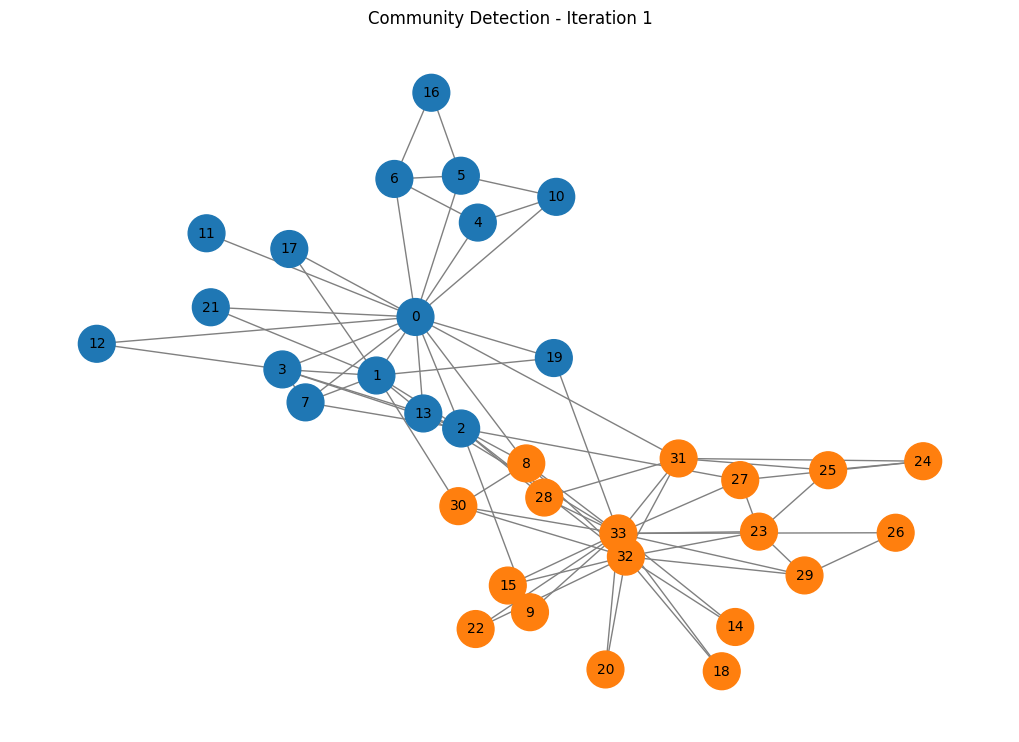

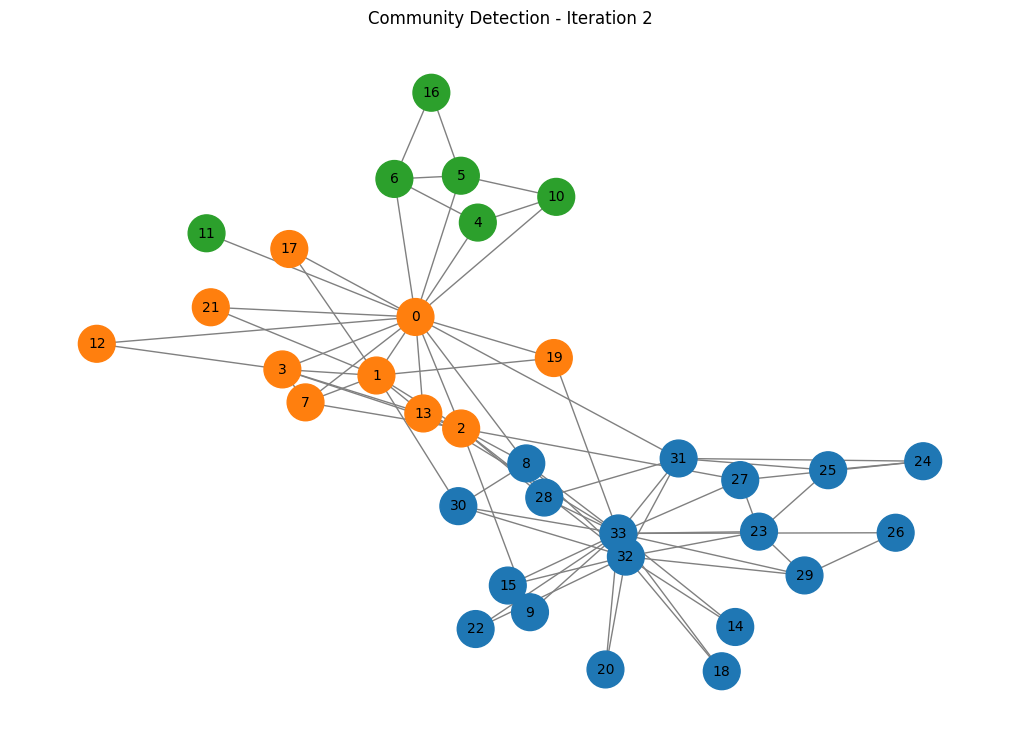

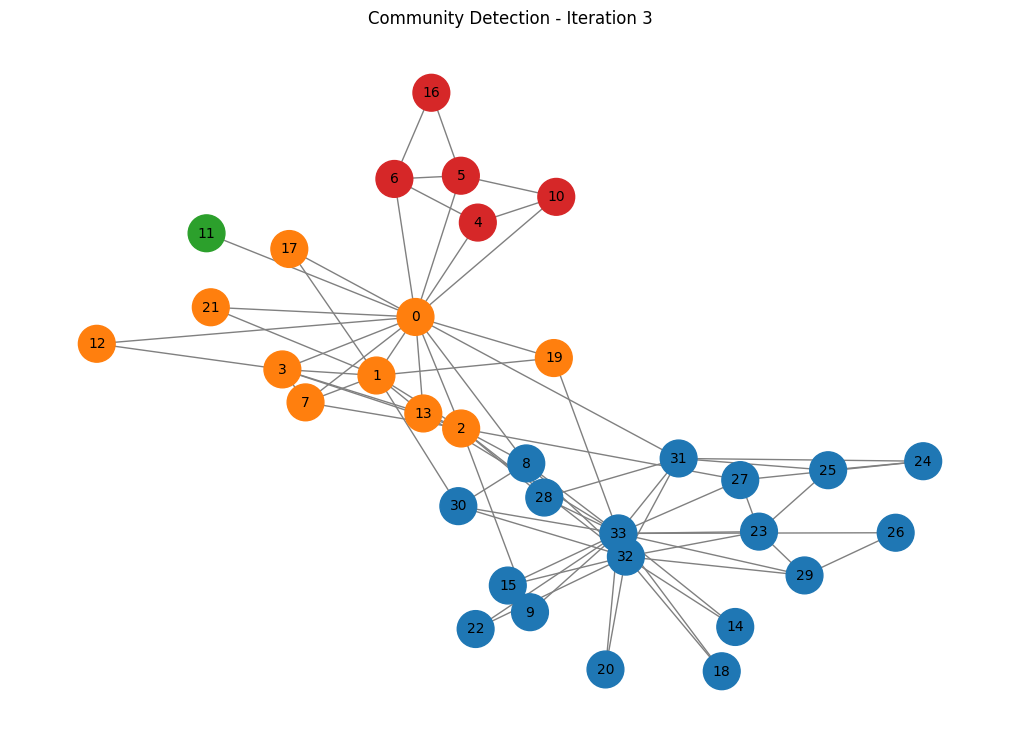

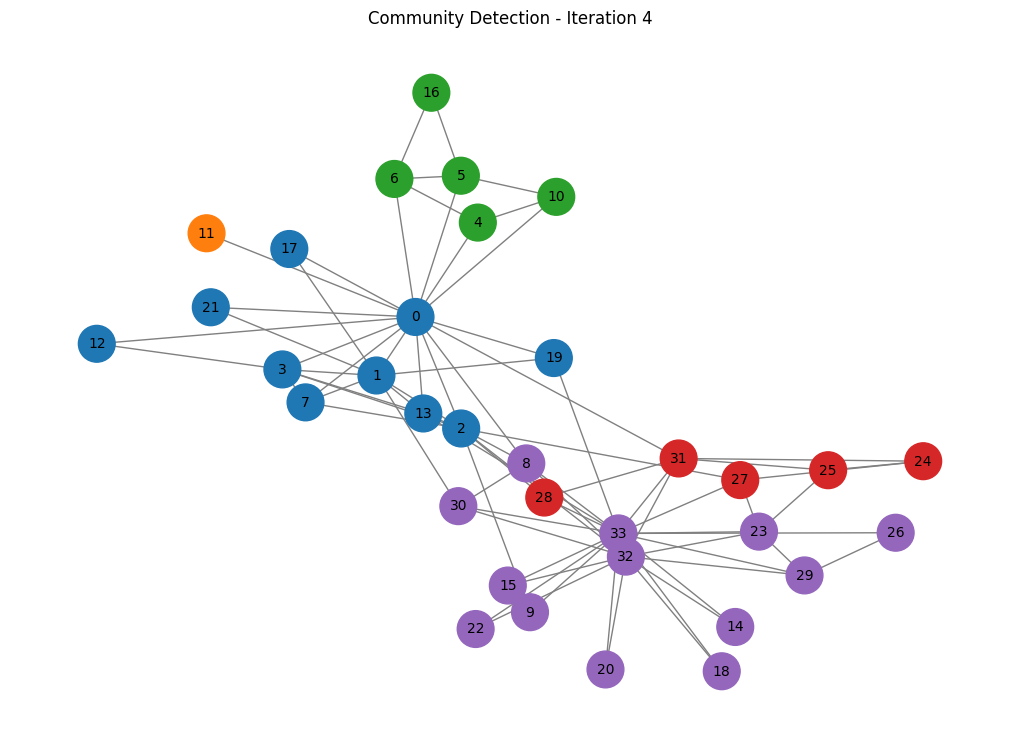

In [136]:

for iteration, partition in enumerate(partition_log, start=1):

    # Give each community a different colour
    colors = ["C" + str(i % 10)
              for i, community in enumerate(partition)]

    node_colors = {}

    for i, community in enumerate(partition):
        for node in community:
            node_colors[node] = colors[i]

    plt.figure(figsize=(10, 7))

    nx.draw(
        karate_graph,
        pos,
        with_labels=True,
        node_color=[node_colors[node] for node in karate_graph.nodes()],
        node_size=700,
        font_size=10,
        edge_color="gray"
    )

    plt.title("Community Detection - Iteration " + str(iteration))
    plt.show()


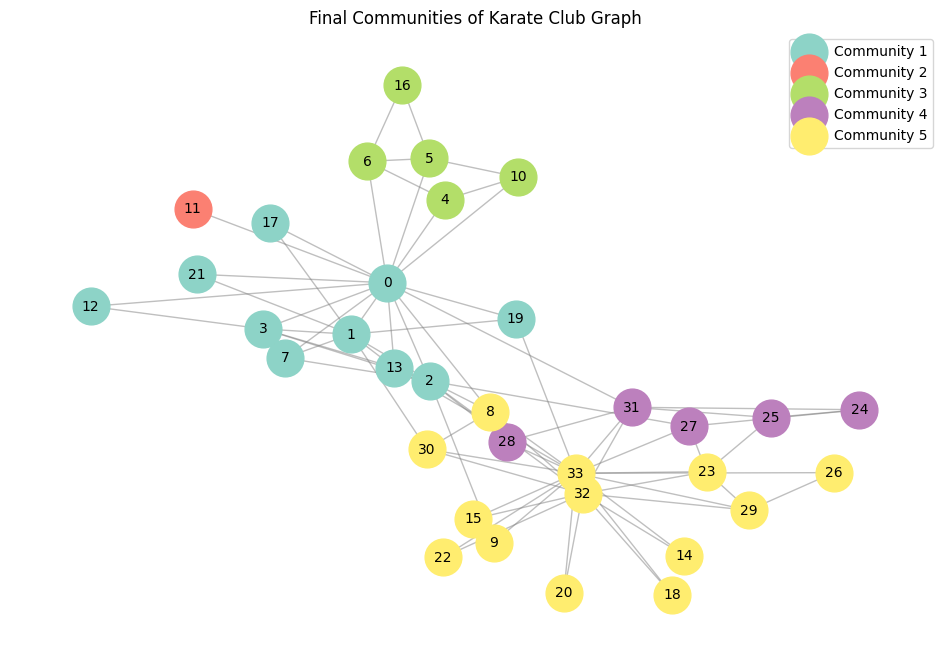

In [137]:
plt.figure(figsize=(12, 8))

colors = plt.cm.Set3(np.linspace(0, 1, len(active_groups)))

for i, community in enumerate(active_groups):
    nx.draw_networkx_nodes(
        karate_graph, pos,
        nodelist=community,
        node_color=[colors[i]],
        node_size=700,
        label=f"Community {i+1}"
    )

nx.draw_networkx_edges(karate_graph, pos, edge_color="gray", alpha=0.5)
nx.draw_networkx_labels(karate_graph, pos, font_size=10)

plt.title("Final Communities of Karate Club Graph")
plt.legend()
plt.axis("off")
plt.show()

## Analysis of Centrality Measures

Four centrality measures are used to understand the importance
of nodes in the network.

### 1. Degree Centrality
Degree centrality measures how many direct connections a node has
relative to the other possible connections in its community.

### 2. Betweenness Centrality
Betweenness centrality measures how frequently a node appears on
shortest paths between other pairs of nodes. It helps identify
important connecting or bridging nodes.

### 3. Closeness Centrality
Closeness centrality measures how close a node is to all other
reachable nodes in its community.

### 4. Clustering Coefficient
The clustering coefficient measures how strongly the neighbours
of a node are connected to one another.

These measures help us understand different structural roles
played by nodes in the network.

In [138]:
# Calculate network metrics
degree = nx.degree_centrality(karate_graph)

betweenness = nx.betweenness_centrality(karate_graph)

closeness = nx.closeness_centrality(karate_graph)

clustering = nx.clustering(karate_graph)

# Display metrics for every node
print("NODE-WISE NETWORK METRICS")
print("-" * 75)

for node in karate_graph.nodes():
    print(
        f"Node {node}: "
        f"Degree = {degree[node]:.4f}, "
        f"Betweenness = {betweenness[node]:.4f}, "
        f"Closeness = {closeness[node]:.4f}, "
        f"Clustering = {clustering[node]:.4f}"
    )

NODE-WISE NETWORK METRICS
---------------------------------------------------------------------------
Node 0: Degree = 0.4848, Betweenness = 0.4376, Closeness = 0.5690, Clustering = 0.1500
Node 1: Degree = 0.2727, Betweenness = 0.0539, Closeness = 0.4853, Clustering = 0.3333
Node 2: Degree = 0.3030, Betweenness = 0.1437, Closeness = 0.5593, Clustering = 0.2444
Node 3: Degree = 0.1818, Betweenness = 0.0119, Closeness = 0.4648, Clustering = 0.6667
Node 4: Degree = 0.0909, Betweenness = 0.0006, Closeness = 0.3793, Clustering = 0.6667
Node 5: Degree = 0.1212, Betweenness = 0.0300, Closeness = 0.3837, Clustering = 0.5000
Node 6: Degree = 0.1212, Betweenness = 0.0300, Closeness = 0.3837, Clustering = 0.5000
Node 7: Degree = 0.1212, Betweenness = 0.0000, Closeness = 0.4400, Clustering = 1.0000
Node 8: Degree = 0.1515, Betweenness = 0.0559, Closeness = 0.5156, Clustering = 0.5000
Node 9: Degree = 0.0606, Betweenness = 0.0008, Closeness = 0.4342, Clustering = 0.0000
Node 10: Degree = 0.0909, Be

In [139]:
community_metrics = {}

for i, nodes in enumerate(active_groups, start=1):

    # Create subgraph for this community
    subgraph = karate_graph.subgraph(nodes)

    # Calculate four metrics
    community_metrics[i] = {
        "Degree": nx.degree_centrality(subgraph),
        "Betweenness": nx.betweenness_centrality(subgraph),
        "Closeness": nx.closeness_centrality(subgraph),
        "Clustering": nx.clustering(subgraph)
    }

    print(f"\nCommunity {i}")
    print("-" * 50)

    for node in nodes:
        print(
            f"Node {node}: "
            f"Degree = {community_metrics[i]['Degree'][node]:.4f}, "
            f"Betweenness = {community_metrics[i]['Betweenness'][node]:.4f}, "
            f"Closeness = {community_metrics[i]['Closeness'][node]:.4f}, "
            f"Clustering = {community_metrics[i]['Clustering'][node]:.4f}"
        )


Community 1
--------------------------------------------------
Node 0: Degree = 1.0000, Betweenness = 0.3542, Closeness = 1.0000, Clustering = 0.3611
Node 1: Degree = 0.8889, Betweenness = 0.2153, Closeness = 0.9000, Clustering = 0.4286
Node 2: Degree = 0.5556, Betweenness = 0.0069, Closeness = 0.6923, Clustering = 0.9000
Node 3: Degree = 0.6667, Betweenness = 0.0625, Closeness = 0.7500, Clustering = 0.6667
Node 7: Degree = 0.4444, Betweenness = 0.0000, Closeness = 0.6429, Clustering = 1.0000
Node 12: Degree = 0.2222, Betweenness = 0.0000, Closeness = 0.5625, Clustering = 1.0000
Node 13: Degree = 0.4444, Betweenness = 0.0000, Closeness = 0.6429, Clustering = 1.0000
Node 17: Degree = 0.2222, Betweenness = 0.0000, Closeness = 0.5625, Clustering = 1.0000
Node 19: Degree = 0.2222, Betweenness = 0.0000, Closeness = 0.5625, Clustering = 1.0000
Node 21: Degree = 0.2222, Betweenness = 0.0000, Closeness = 0.5625, Clustering = 1.0000

Community 2
------------------------------------------------

In [140]:
centrality_log = {
    "Degree": [],
    "Betweenness": [],
    "Closeness": [],
    "Clustering": []
}

for partition in partition_log:

    degree_values = {}
    betweenness_values = {}
    closeness_values = {}
    clustering_values = {}

    for community in partition:

        subgraph = karate_graph.subgraph(community)

        degree_values.update(nx.degree_centrality(subgraph))
        betweenness_values.update(nx.betweenness_centrality(subgraph))
        closeness_values.update(nx.closeness_centrality(subgraph))
        clustering_values.update(nx.clustering(subgraph))

    centrality_log["Degree"].append(degree_values)
    centrality_log["Betweenness"].append(betweenness_values)
    centrality_log["Closeness"].append(closeness_values)
    centrality_log["Clustering"].append(clustering_values)

print("Metrics calculated for", len(partition_log), "iterations.")

Metrics calculated for 4 iterations.


In [ ]:
centrality_sets = {
    "Degree Centrality": degree,
    "Betweenness Centrality": betweenness,
    "Closeness Centrality": closeness,
    "Clustering Coefficient": clustering
}
for label, scores in centrality_sets.items():
    print("\\n" + label)
    print("-" * 40)
    leaders = sorted(scores.items(), key=lambda pair: pair[1], reverse=True)[:5]
    for node_id, score in leaders:
        print(f"Node {node_id}: {score:.4f}")

In [143]:

def calculate_partition_modularity(partition):
    Q = 0

    for community in partition:
        B_sub = modularity[np.ix_(community, community)]
        Q += np.sum(B_sub)

    return Q / (2 * edge_total)


# Include the original partition before any split
all_partitions = [[list(karate_graph.nodes())]] + partition_log

q_history = []

for iteration, partition in enumerate(all_partitions):
    Q = calculate_partition_modularity(partition)
    q_history.append(Q)

    print("Iteration:", iteration)
    print("Number of communities:", len(partition))
    print("Modularity Q:", round(Q, 6))
    print("-" * 35)


Iteration: 0
Number of communities: 1
Modularity Q: -0.0
-----------------------------------
Iteration: 1
Number of communities: 2
Modularity Q: 0.371466
-----------------------------------
Iteration: 2
Number of communities: 3
Modularity Q: 0.389793
-----------------------------------
Iteration: 3
Number of communities: 4
Modularity Q: 0.391108
-----------------------------------
Iteration: 4
Number of communities: 5
Modularity Q: 0.409435
-----------------------------------


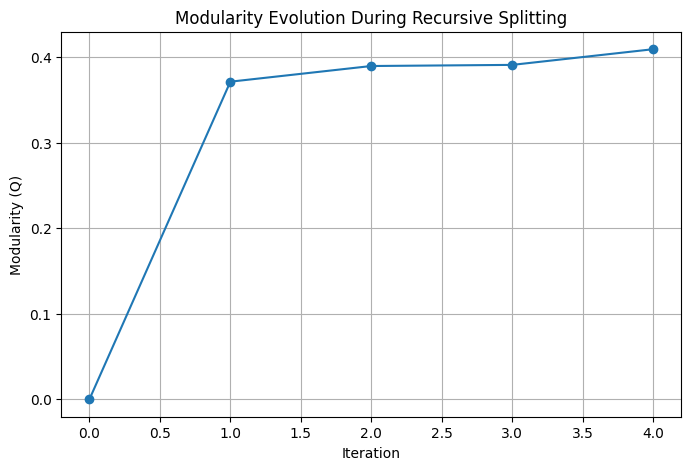

In [142]:

plt.figure(figsize=(8, 5))

plt.plot(range(len(q_history)),
         q_history,
         marker="o")

plt.xlabel("Iteration")
plt.ylabel("Modularity (Q)")
plt.title("Modularity Evolution During Recursive Splitting")
plt.grid(True)
plt.show()


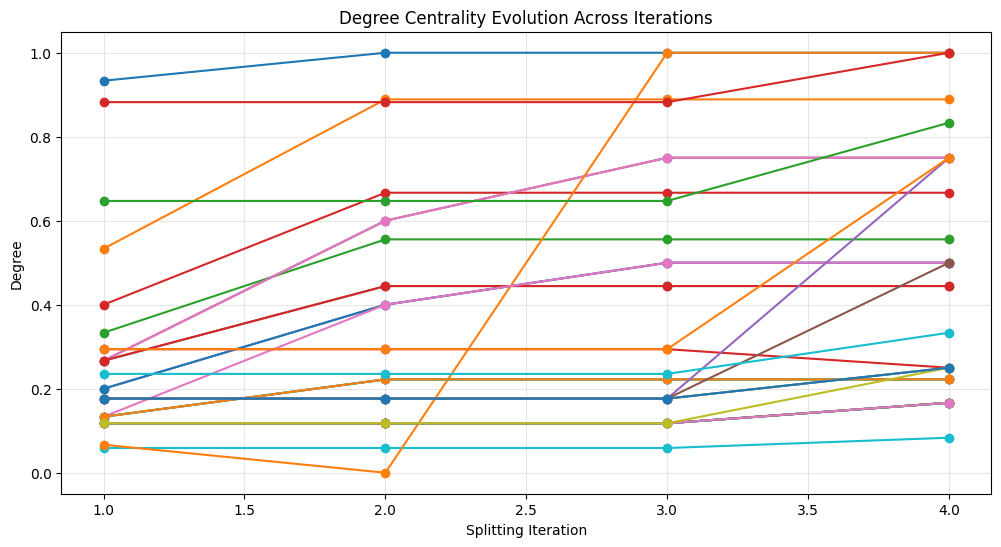

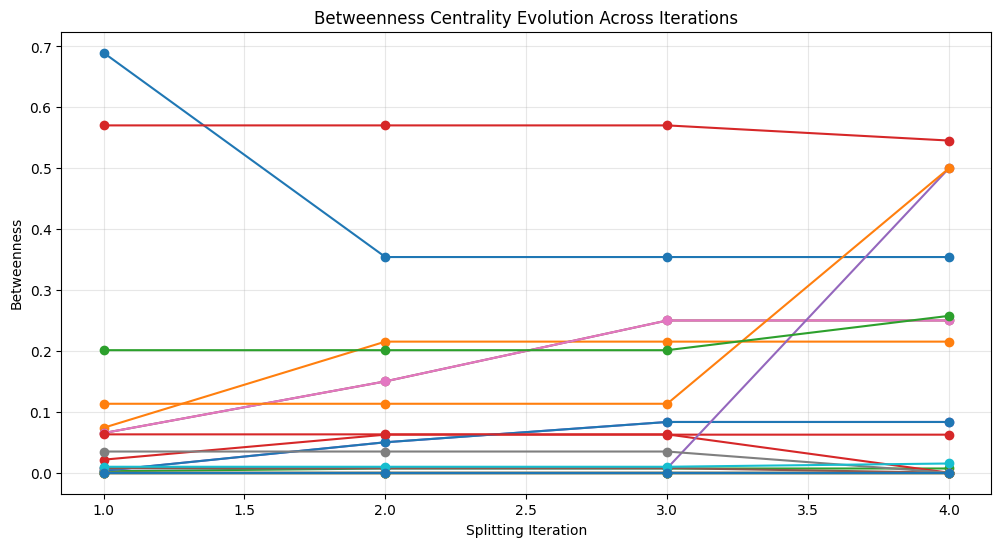

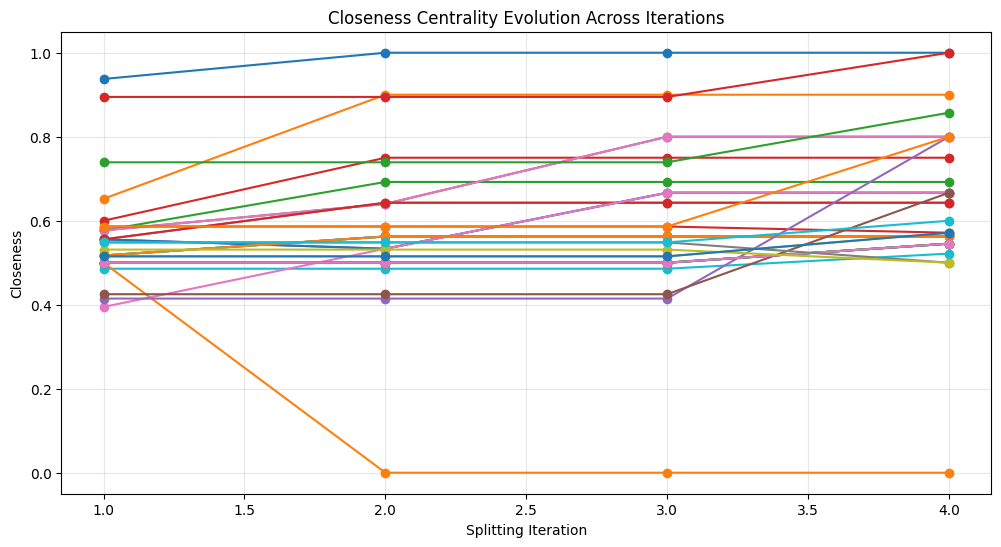

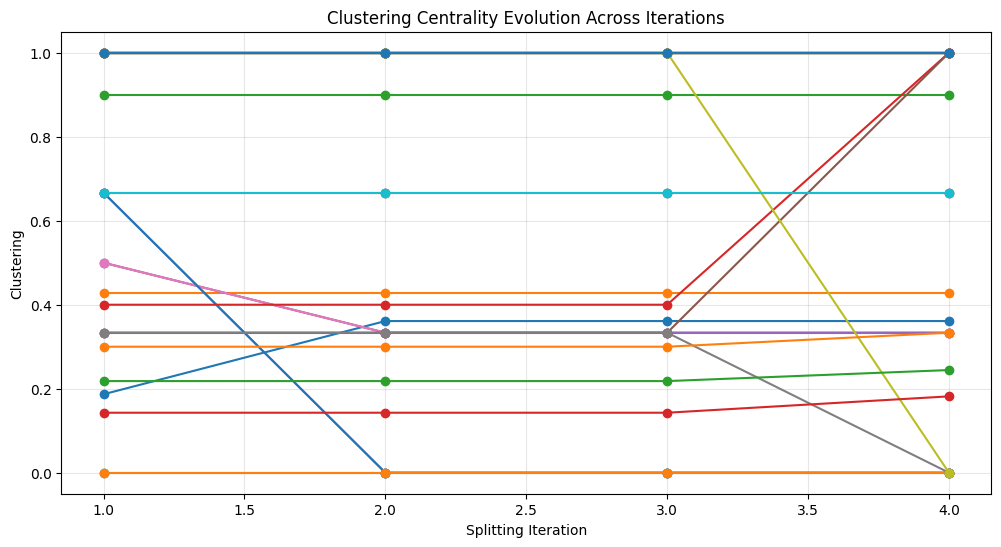

In [144]:
metric_names = ["Degree", "Betweenness", "Closeness", "Clustering"]

for metric in metric_names:

    plt.figure(figsize=(12, 6))

    for node in karate_graph.nodes():

        values = [
            iteration[node]
            for iteration in centrality_log[metric]
        ]

        plt.plot(
            range(1, len(values) + 1),
            values,
            marker="o",
            label=f"Node {node}"
        )

    plt.title(f"{metric} Centrality Evolution Across Iterations")
    plt.xlabel("Splitting Iteration")
    plt.ylabel(metric)
    plt.grid(True, alpha=0.3)
    plt.show()

## Heatmap Visualization and Interpretation

Heatmaps are used to visualize the changes in centrality measures
during recursive community splitting.

In each heatmap:

- Rows represent individual nodes.
- Columns represent iterations of community splitting.
- Colours represent the values of the corresponding metric.

Brighter colours indicate higher values, while darker colours
indicate lower values.

By comparing the colours across iterations, we can observe how
the structural importance of individual nodes changes as the
network is divided into smaller communities.

The four heatmaps represent degree centrality, betweenness
centrality, closeness centrality, and clustering coefficient.

In [ ]:
metric_columns = [
    ("Degree", "Degree Centrality"),
    ("Betweenness", "Betweenness Centrality"),
    ("Closeness", "Closeness Centrality"),
    ("Clustering", "Clustering Coefficient")
]
for metric_key, heading in metric_columns:
    frame = pd.DataFrame(
        {
            f"Iteration {step + 1}": [
                centrality_log[step][metric_key][node_id]
                for node_id in karate_graph.nodes()
            ]
            for step in range(len(centrality_log))
        },
        index=list(karate_graph.nodes())
    )
    plt.figure(figsize=(12, 8))
    sns.heatmap(frame, cmap="viridis", annot=False, linewidths=0.3)
    plt.title(heading + " Heatmap")
    plt.xlabel("Recursive splitting iteration")
    plt.ylabel("Node ID")
    plt.tight_layout()
    plt.show()


## Conclusion

In this assignment, spectral community detection was applied
to the Karate Club graph using the modularity matrix.

The network was divided recursively using the leading
eigenvectors of restricted modularity matrices. The largest
eigenvalue was used to determine whether a community could
be further divided.

Modularity was calculated after each successful split to
study the quality of the resulting community structure.

Four centrality measures were also calculated and visualized
using heatmaps. These measures helped us understand how the
importance and connectivity of nodes changed during the
community detection process.

Overall, spectral community detection provides a mathematical
approach to identifying meaningful communities and studying
the structure of complex networks.
